# Evaluacion Parcial 1: Agente Inteligente de Soporte TI (SupportAi)
--------------------------------------------------------------------
# Presentacion del Caso y Contexto de nuestra Empresa

Nosotros como equipo hemos diseñado un proyecto orientado a resolver un cuello de botella muy comun en el mundo real: **la saturacion de las mesas de ayuda de TI**.

Para este proyecto, creamos la empresa **SupportAi**, basandonos en la operacion de sistemas de tickets reales como **Jira Service Desk**. En nuestra organizacion, el equipo de soporte de Nivel 1 esta abrumado. Diariamente, los tecnicos invierten mas del 50% de su tiempo respondiendo manualmente las mismas 6 preguntas:
1. ¿Como cambio mi contraseña?
2. ¿Como configuro el correo institucional?
3. ¿Que hago si se bloqueo mi cuenta?
4. ¿Como solicito acceso a una aplicacion?
5. ¿Como conecto el computador al Wi-Fi?
6. ¿Cual es el procedimiento para reportar un problema?

# 2. Problema y Solucion
Tambien detectamos que no podiamos simplemente conectar un LLM tradicional. Si lo haciamos, la IA podria **alucinar** y darle al trabajador instrucciones que no corresponden a las reglas de nuestra compañia (ej. inventar que la contraseña tenga 4 numeros, cuando por regla exigimos 12 caracteres).

Por ello, diseñamos una solucion basada en una arquitectura **RAG (Generacion Aumentada de Recuperacion)**.
El flujo metodologico que creamos es:
1. **Recuperacion (Retrieval):** Cuando el usuario hace la pregunta, no se la pasamos de inmediato a la IA. Primero, buscamos en nuestra base de datos el manual que resuelve esa duda especifica.
2. **Generacion:** Luego, le pasamos ese manual al modelo (Groq) y le obligamos a que redacte una respuesta amigable **basandose unicamente** en nuestra documentacion oficial.

In [1]:
# Librerias
!pip install -q openai faiss-cpu sentence-transformers matplotlib pandas numpy

In [2]:
# Conexion con LLM (GROQ)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import faiss
from sentence_transformers import SentenceTransformer
from openai import OpenAI
from google.colab import userdata

# el cerebro GROQ
api_key = userdata.get("GROQ_API_KEY")
if not api_key:
    print(" ADVERTENCIA: No se encontro la API KEY.")
else:
    # Creamos el cliente de IA
    client = OpenAI(api_key=api_key, base_url="https://api.groq.com/openai/v1")
    print(" Cliente LLM configurado correctamente con Groq.")

 Cliente LLM configurado correctamente con Groq.


## 3. Arquitectura de Datos y Motor RAG

Cargamos nuestro xlsx donde esta la Base de Datos

### **¿Porque esta Arquitectura?:**
Para el modulo de busqueda usamos **FAISS**.
Cuando un empleado realiza una consulta, el sistema convierte su pregunta en un vector y lo compara con los vectores correspondientes a los manuales. De esta manera, podemos identificar matematicamente que contenido es mas similar o relevante para responder a la consulta.

In [3]:
# Excel
from google.colab import files
df = pd.read_excel("SupportAi_BaseConocimiento.xlsx")

print("Base de conocimiento cargada correctamente.")
print("Cantidad de procedimientos:", len(df))
display(df.head(7))

Base de conocimiento cargada correctamente.
Cantidad de procedimientos: 18


,ID,Categoría,Título,Procedimiento,Palabras clave,Área responsable,Prioridad,Canal/Sistema,SLA/Referencia,Estado
0,1,Seguridad,Cambio de contraseña,"Para cambiar la contraseña, ingrese al portal ...",contraseña;clave;renovar;cambiar contraseña;pa...,Seguridad TI,Media,MySupport,Cada 90 días,Activo
1,2,Correo,Configuración de correo institucional,"Abra Microsoft Outlook, seleccione 'Agregar cu...",correo;Outlook;Office 365;MFA;correo instituci...,Soporte TI,Media,Outlook / Authenticator,Según necesidad,Activo
2,3,Seguridad,Cuenta bloqueada,Si su cuenta fue bloqueada por intentos fallid...,cuenta bloqueada;bloqueo;intentos fallidos;des...,Seguridad TI,Alta,Anexo 5050 / WhatsApp soporte,Inmediato,Activo
3,4,Aplicaciones,Solicitud de acceso a aplicaciones,"Para solicitar acceso a un nuevo software, por...",SAP;Adobe;Figma;Canva;software;aplicación;Acce...,Soporte TI,Media,Jira Service Desk,Según necesidad,Activo
4,5,Redes,Conexión Wi-Fi corporativa,"Estando en la oficina, busque la red inalámbri...",wifi;Wi-Fi;red;internet;SupportAi_Corp_5G;cone...,Redes,Alta,SupportAi_Corp_5G,Según necesidad,Activo
5,6,Incidentes,Reportar un problema general,"Ante cualquier falla física del equipo, caída ...",problema;error;internet;pantalla azul;falla;in...,Mesa de Ayuda,Alta,Jira Service Desk,Menos de 2 horas,Activo
6,7,Hardware,Equipo no enciende,"Si el computador no enciende, no intente abrir...",computador;PC;no enciende;hardware;equipo;falla,Hardware,Alta,Jira Service Desk,Menos de 2 horas,Activo


In [4]:
documentos_internos = (df["Título"] + ": " + df["Procedimiento"]).tolist()

# 2. Motor de búsqueda FAISS
modelo_embeddings = SentenceTransformer("all-MiniLM-L6-v2")

# Convertimos los documentos en vectores
vectores = modelo_embeddings.encode(documentos_internos)
print("Embeddings creados correctamente")

dimension = vectores.shape[1]
indice_faiss = faiss.IndexFlatL2(dimension)
indice_faiss.add(vectores.astype("float32"))

print("Motor RAG inicializado correctamente")
print("Documentos Encontrados:", indice_faiss.ntotal)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embeddings creados correctamente
Motor RAG inicializado correctamente
Documentos Encontrados: 18


## 4. Diseño y Formulacion del Prompt

Para el diseño del prompt, necesitabamos garantizar que la IA hablara en tono profesional y que no inventara cosas.

**Justificacion System Prompt:**
Creamos una **REGLA CRITICA**. Le indicamos explicitamente al modelo que, si la informacion de FAISS no contiene una respuesta para la consulta del usuario, el agente debe reconocer que no tiene la informacion suficiente y lo llevaria a la mesa de ayuda humana.

Con esto evitamos que nuestra **Inteligencia** Mienta y que no ocacione otro problema.

In [5]:
# RAG
def agente_soporte_ti(pregunta):
    vector_pregunta = modelo_embeddings.encode(
    [pregunta]).astype("float32")

    # Buscar los 3 documentos más parecidos
    distancias, indices = indice_faiss.search(
    vector_pregunta,3)

    documentos = []
    for indice in indices[0]:
        documentos.append(documentos_internos[indice])

    contexto = "\n---\n".join(documentos)

    # Instrucciones
    prompt = """
    Eres SupportAi, un asistente de soporte TI.

    Responde solamente utilizando la información
    entregada en el contexto.

    No inventes información.

    Si la respuesta no aparece en el contexto,
    responde:

    "Lo siento, no tengo informacion oficial sobre
    este procedimiento. Por favor contacta a la
    mesa de ayuda."

    Responde de forma clara y amable.
    """

    mensaje = f"""Contexto:
    {contexto}
    Pregunta:
    {pregunta}
    """
    # Enviar pregunta a Groq
    respuesta = client.chat.completions.create(
        model="openai/gpt-oss-20b",
        messages=[
            { "role": "system",
              "content": prompt
            },
            { "role": "user",
              "content": mensaje
            }],temperature=0.2)

    return respuesta.choices[0].message.content, contexto

## 5. Evaluacion de Coherencia y Resultados Reales

En esta prueba demostramos la coherencia de nuestro sistema. Simularemos ser 3 empleados haciendo preguntas de soporte. Vamos a imprimir en pantalla tanto el **Manual que encontro el RAG** como la **Respuesta final del Bot**, para demostrar que el modelo respetó fielmente los datos que nosotros le dimos.

In [6]:
# Chat SupportAi
print(" SupportAi - SOPORTE TI ")

print("Escribe tu problema de soporte TI.")
print("Escribe 'salir' para terminar.")

while True:
    pregunta = input("Tú: ")
    if pregunta.lower() == "salir":
        print("SupportAi: ¡Hasta luego!")
        break

    respuesta, documento = agente_soporte_ti(pregunta)
    print("SupportAi:")
    print(respuesta)


 SupportAi - SOPORTE TI 
Escribe tu problema de soporte TI.
Escribe 'salir' para terminar.
Tú: salir
SupportAi: ¡Hasta luego!


## 6. Dashboard y Conclusiones del Proyecto

Como equipo, programamos este dashboard usando `matplotlib` para evaluar el impacto de nuestra solucion en el negocio. Este grafico de barras ilustra y justifica por que este proyecto es util: logramos reducir los tiempos de resolucion del nivel 1 de soporte de minutos a milisegundos, justificando con creces la implementacion de esta arquitectura.

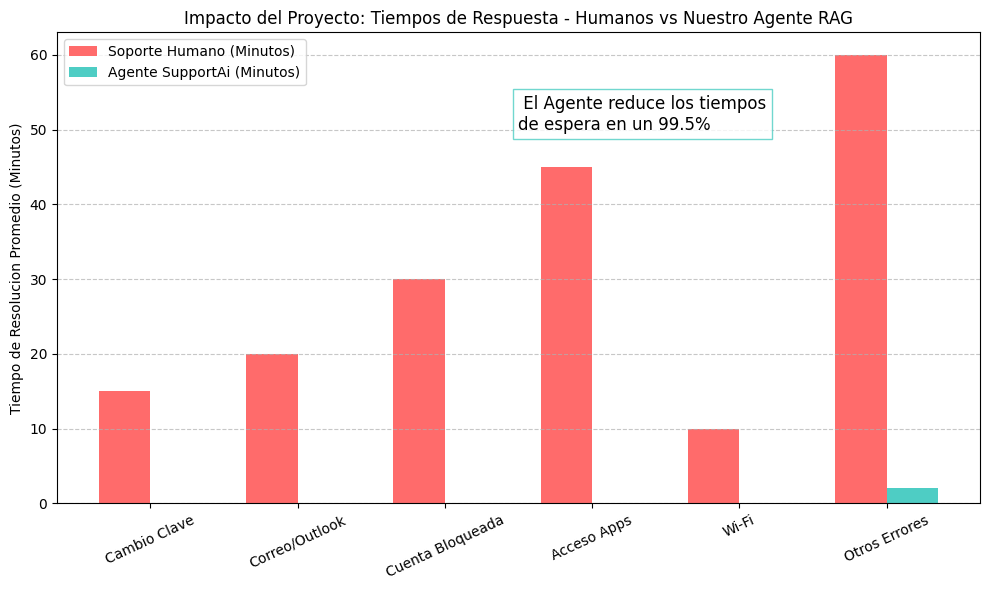

 Grafico listo.


In [7]:
categorias = ['Cambio Clave', 'Correo/Outlook', 'Cuenta Bloqueada', 'Acceso Apps', 'Wi-Fi', 'Otros Errores']
tiempo_humano_minutos = [15, 20, 30, 45, 10, 60]      # Tiempo del humano
tiempo_agente_minutos = [0.1, 0.1, 0.1, 0.1, 0.1, 2] # Tiempo de nuestro modelo IA

plt.figure(figsize=(10, 6))
x = np.arange(len(categorias))
width = 0.35

plt.bar(x - width/2, tiempo_humano_minutos, width, label='Soporte Humano (Minutos)', color='#FF6B6B')
plt.bar(x + width/2, tiempo_agente_minutos, width, label='Agente SupportAi (Minutos)', color='#4ECDC4')

plt.ylabel('Tiempo de Resolucion Promedio (Minutos)')
plt.title('Impacto del Proyecto: Tiempos de Respuesta - Humanos vs Nuestro Agente RAG')
plt.xticks(x, categorias, rotation=25)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.text(2.5, 50, " El Agente reduce los tiempos\nde espera en un 99.5%",
         fontsize=12, bbox=dict(facecolor='white', alpha=0.8, edgecolor='#4ECDC4'))

plt.tight_layout()
plt.show()

print(" Grafico listo.")

# Evaluación Parcial 2: Desarrollo e Integración de un Agente Inteligente de Soporte TI (SupportAi)

Asignatura: ISY0101 — Ingeniería de Soluciones con IA
Proyecto: SupportAi — Agente inteligente de soporte TI corporativo
Integrantes: John Lara y Justin Galleguillos

# Objetivo

Ampliar el agente de soporte TI desarrollado en la Evaluación Parcial 1, incorporando herramientas para consultar manuales oficiales y gestionar tickets, junto con memoria conversacional y capacidades de interacción para atender incidentes de soporte TI.

In [8]:
#librerias.
!pip install -q langchain langchain-groq langchain-community langgraph

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


# 7. Integración de Herramientas del Agente
Definición de las herramientas para consultar los manuales oficiales y registrar incidentes de soporte TI.

In [9]:
from langchain.tools import tool

@tool
def buscar_manual(pregunta: str) -> str:
    """Consulta los manuales oficiales de SupportAi mediante el sistema RAG de FAISS."""
    respuesta, contexto = agente_soporte_ti(pregunta)
    return respuesta


# 8. Sistema de Gestión de Tickets

Implementación del registro de incidentes, asignación de identificadores y seguimiento de solicitudes.

In [10]:
import json
import os
from datetime import datetime

ARCHIVO_TICKETS = "supportai_tickets.json"
ARCHIVO_MEMORIA = "supportai_memoria.json"

def cargar_json(ruta):
    if os.path.exists(ruta):
        try:
            with open(ruta, "r", encoding="utf-8") as archivo:
                return json.load(archivo)
        except (json.JSONDecodeError, OSError):
            return []
    return []

def guardar_json(ruta, datos):
    with open(ruta, "w", encoding="utf-8") as archivo:
        json.dump(datos, archivo, ensure_ascii=False, indent=2)

tickets = cargar_json(ARCHIVO_TICKETS)
memorias_incidentes = cargar_json(ARCHIVO_MEMORIA)

def normalizar_texto(texto):
    return " ".join(texto.lower().strip().split())

def guardar_memoria_incidente(descripcion, ticket_id=None, resultado=""):
    registro = {
        "fecha": datetime.now().isoformat(timespec="seconds"),
        "descripcion": descripcion,
        "ticket_id": ticket_id,
        "resultado": resultado
    }
    memorias_incidentes.append(registro)
    guardar_json(ARCHIVO_MEMORIA, memorias_incidentes)
    # Actualizar el índice semántico para que el nuevo incidente pueda recuperarse.
    if "reconstruir_indice_memoria" in globals():
        reconstruir_indice_memoria()

@tool
def crear_ticket(descripcion: str) -> str:
    """Registra un incidente TI no resuelto. Evita duplicar tickets abiertos con la misma descripción."""
    descripcion_limpia = descripcion.strip()
    if not descripcion_limpia:
        return "No se creó el ticket: la descripción está vacía."

    clave = normalizar_texto(descripcion_limpia)
    for ticket in tickets:
        if normalizar_texto(ticket["descripcion"]) == clave and ticket["estado"] == "Abierto":
            return f"Ya existe un ticket abierto para este incidente: {ticket['id']}. No se creó un duplicado."

    ticket_id = f"TCK-{len(tickets)+1:03d}"
    ticket = {
        "id": ticket_id,
        "descripcion": descripcion_limpia,
        "estado": "Abierto",
        "prioridad": "Por evaluar",
        "fecha": datetime.now().isoformat(timespec="seconds")
    }
    tickets.append(ticket)
    guardar_json(ARCHIVO_TICKETS, tickets)
    guardar_memoria_incidente(descripcion_limpia, ticket_id, "Ticket creado")
    return f"Ticket {ticket_id} creado correctamente y quedó en estado Abierto."

@tool
def consultar_ticket(ticket_id: str) -> str:
    """Busca un ticket por su identificador y devuelve su estado."""
    for ticket in tickets:
        if ticket["id"].lower() == ticket_id.strip().lower():
            return json.dumps(ticket, ensure_ascii=False)
    return f"No se encontró el ticket {ticket_id}."

print(f"Tickets cargados: {len(tickets)}")
print(f"Incidentes guardados en memoria: {len(memorias_incidentes)}")


Tickets cargados: 0
Incidentes guardados en memoria: 0


In [11]:
import pandas as pd

def mostrar_tickets():
    tickets_actuales = cargar_json(ARCHIVO_TICKETS)

    if not tickets_actuales:
        return pd.DataFrame(columns=[
            "ID", "Problema", "Estado", "Prioridad", "Fecha de creación"
        ])

    return pd.DataFrame([
        {
            "ID": ticket["id"],
            "Problema": ticket["descripcion"],
            "Estado": ticket["estado"],
            "Prioridad": ticket["prioridad"],
            "Fecha de creación": ticket["fecha"]
        }
        for ticket in tickets_actuales
    ])

# 9. Configuración del Agente Inteligente

Integración del modelo de lenguaje con LangChain y definición de las instrucciones de comportamiento de SupportAi.

# 10. Memoria Conversacional y Recuperación de Contexto

Configuración de la memoria para mantener la continuidad de la conversación y recordar los problemas reportados por el usuario.

In [12]:

from langchain.tools import tool

@tool
def planificar_atencion(problema: str) -> str:
    """
    Analiza un incidente de soporte TI y propone una prioridad
    y una secuencia inicial de atención.
    """
    texto = problema.lower()

    if any(p in texto for p in [
        "servidor caido", "servidor caído",
        "sistema caido", "sistema caído",
        "empresa detenida", "todos sin acceso",
        "red completa caída", "red completa caida"
    ]):
        prioridad = "Crítica"
    elif any(p in texto for p in [
        "no funciona", "no conecta", "sin internet",
        "no puedo acceder", "bloqueado",
        "error", "wifi", "wi-fi"
    ]):
        prioridad = "Alta"
    else:
        prioridad = "Normal"

    plan = [
        "1. Identificar el problema y confirmar su alcance.",
        "2. Consultar los procedimientos oficiales del manual.",
        "3. Aplicar únicamente las instrucciones documentadas.",
        "4. Verificar con el usuario si el problema se resolvió.",
        "5. Si continúa, registrar o escalar mediante un ticket."
    ]

    resultado = {
        "problema": problema,
        "prioridad_sugerida": prioridad,
        "plan_de_atencion": plan
    }

    return json.dumps(resultado, ensure_ascii=False, indent=2)

print("Herramienta planificar_atencion inicializada.")


Herramienta planificar_atencion inicializada.


In [15]:
from langchain_groq import ChatGroq
from langchain.agents import create_agent
from langgraph.checkpoint.memory import InMemorySaver

# Modelo de lenguaje
llm = ChatGroq(
    groq_api_key=api_key,
    model="openai/gpt-oss-20b",
    temperature=0.2
)

# Herramientas disponibles para el agente
herramientas = [
    buscar_manual,
    planificar_atencion,
    buscar_incidentes_previos,
    crear_ticket,
    consultar_ticket
]

# Memoria conversacional de corto plazo
memoria = InMemorySaver()

system_prompt = """
Eres SupportAi, un agente corporativo de soporte TI de Nivel 1.

OBJETIVO:
Resolver consultas de TI con procedimientos oficiales, mantener continuidad y registrar incidentes no resueltos.

PLANIFICACIÓN Y DECISIONES:
1. Identifica si la solicitud pertenece a soporte TI. Si no pertenece, recházala cordialmente y no uses herramientas.
2. Para un incidente TI, usa planificar_atencion para establecer una secuencia y prioridad inicial.
3. Consulta buscar_incidentes_previos cuando el problema pueda relacionarse con antecedentes anteriores o cuando el usuario mencione un caso previo.
4. Consulta buscar_manual antes de entregar instrucciones técnicas. No inventes pasos ni agregues recomendaciones que no estén respaldadas por el manual.
5. Expón los pasos oficiales de forma clara y pregunta si el problema se resolvió.
6. Si el usuario confirma que se resolvió, no crees un ticket.
7. Si el usuario indica que no se resolvió, o el procedimiento no contiene una solución suficiente, crea un ticket con crear_ticket.
8. Si el usuario entrega un identificador, usa consultar_ticket para revisar su estado.
9. Si crear_ticket informa que ya existe un ticket abierto, informa ese identificador y no intentes crear otro.
10. Nunca afirmes que una herramienta se ejecutó si no devolvió confirmación.

SEGURIDAD Y ALCANCE:
- Responde sobre procedimientos corporativos únicamente con respaldo de los manuales oficiales.
- Para temas ajenos a TI, responde: "Lo siento, no tengo información oficial sobre este tema. Por favor, contacta al área correspondiente."
- No solicites contraseñas ni datos sensibles.
- No prometas tiempos de solución ni visitas técnicas que no estén documentadas.
- Distingue entre prioridad sugerida y prioridad oficialmente asignada.
- Mantén un tono profesional, breve y amable.

MEMORIA:
- Usa el historial de la conversación actual para entender seguimientos.
- Usa buscar_incidentes_previos para recuperar antecedentes semánticamente relacionados.
- No presentes un incidente anterior como si fuera necesariamente el mismo incidente actual.
"""

agente = create_agent(
    model=llm,
    tools=herramientas,
    system_prompt=system_prompt,
    checkpointer=memoria
)

configuracion = {"configurable": {"thread_id": "supportai-demo"}}

def conversar_supportai(pregunta, thread_id="supportai-demo"):
    """Envía un mensaje al agente y conserva el contexto del thread indicado."""
    resultado = agente.invoke(
        {"messages": [{"role": "user", "content": pregunta}]},
        config={"configurable": {"thread_id": thread_id}}
    )
    return resultado["messages"][-1].content

print("SupportAi inicializado con herramientas, memoria y planificación.")


SupportAi inicializado con herramientas, memoria y planificación.


## 10. Planificación adaptativa y memoria semántica

SupportAi mantiene el historial de cada conversación mediante `InMemorySaver`. Además, conserva incidentes y tickets en archivos JSON y permite recuperar incidentes anteriores por similitud semántica usando los embeddings del mismo modelo de la Evaluación 1 y un índice FAISS independiente.

La herramienta de planificación propone una secuencia de atención y una prioridad inicial según la información del incidente. El agente puede combinar esta planificación con la consulta del manual, la búsqueda de antecedentes y la creación o consulta de tickets.

In [14]:
# Índice semántico de incidentes anteriores (separado del índice de manuales)
import faiss
import numpy as np

def reconstruir_indice_memoria():
    global indice_memoria, vectores_memoria
    indice_memoria = faiss.IndexFlatIP(modelo_embeddings.get_embedding_dimension())
    vectores_memoria = None

    if memorias_incidentes:
        textos = [
            f"{m.get('descripcion', '')} {m.get('resultado', '')}"
            for m in memorias_incidentes
        ]
        vectores_memoria = modelo_embeddings.encode(
            textos, normalize_embeddings=True
        ).astype("float32")
        indice_memoria.add(vectores_memoria)

reconstruir_indice_memoria()

@tool
def buscar_incidentes_previos(consulta: str) -> str:
    """Recupera incidentes anteriores semánticamente relacionados con la consulta actual."""
    if not memorias_incidentes or indice_memoria.ntotal == 0:
        return "Todavía no existen incidentes anteriores almacenados."

    vector = modelo_embeddings.encode(
        [consulta], normalize_embeddings=True
    ).astype("float32")
    cantidad = min(3, indice_memoria.ntotal)
    similitudes, indices = indice_memoria.search(vector, cantidad)

    resultados = []
    for similitud, indice in zip(similitudes[0], indices[0]):
        if indice >= 0:
            registro = memorias_incidentes[int(indice)]
            resultados.append({
                "similitud": round(float(similitud), 3),
                "fecha": registro.get("fecha"),
                "descripcion": registro.get("descripcion"),
                "ticket_id": registro.get("ticket_id"),
                "resultado": registro.get("resultado")
            })
    return json.dumps(resultados, ensure_ascii=False, indent=2)

@tool
def planificar_atencion(descripcion: str) -> str:
    """Analiza un incidente y propone prioridad y pasos ordenados de atención."""
    texto = normalizar_texto(descripcion)
    criticos = ["servidor caido", "servidor caído", "sin sistema", "empresa detenida",
                "todos los usuarios", "ataque", "robo de informacion", "robo de información"]
    altos = ["no puedo trabajar", "sin acceso", "cuenta bloqueada", "correo caido",
             "correo caído", "red completa", "wifi de toda la oficina"]

    if any(p in texto for p in criticos):
        prioridad = "Crítica"
        pasos = [
            "1. Confirmar alcance e impacto del incidente.",
            "2. Consultar el procedimiento oficial relacionado.",
            "3. Si el procedimiento no resuelve el incidente, escalar inmediatamente mediante ticket."
        ]
    elif any(p in texto for p in altos):
        prioridad = "Alta"
        pasos = [
            "1. Identificar usuario, servicio afectado y alcance.",
            "2. Consultar el manual oficial y aplicar únicamente sus pasos.",
            "3. Si persiste el problema, crear o recuperar el ticket correspondiente."
        ]
    else:
        prioridad = "Normal"
        pasos = [
            "1. Precisar el síntoma y recopilar información faltante.",
            "2. Consultar el manual oficial más pertinente.",
            "3. Verificar con el usuario si la solución funcionó.",
            "4. Si no se resuelve, registrar el incidente en un ticket."
        ]

    return json.dumps({"prioridad_sugerida": prioridad, "plan_de_atencion": pasos},
                      ensure_ascii=False, indent=2)

print("Memoria semántica e índice FAISS de incidentes inicializados.")
print("Incidentes indexados:", indice_memoria.ntotal)


Memoria semántica e índice FAISS de incidentes inicializados.
Incidentes indexados: 0


## 11. Interacción con SupportAi
Ejecuta esta celda para conversar con el agente. La memoria conversacional se conserva mientras se utilice el mismo identificador de conversación.

In [16]:
print("SUPPORTAI - SOPORTE TI")
print("Escribe 'salir' para terminar la conversación.")

while True:
    pregunta = input("Tú: ").strip()
    if pregunta.lower() == "salir":
        print("SupportAi: Hasta luego.")
        break
    if not pregunta:
        continue
    try:
        print("SupportAi:", conversar_supportai(pregunta))
    except Exception as error:
        print("No se pudo procesar la consulta:", str(error))


SUPPORTAI - SOPORTE TI
Escribe 'salir' para terminar la conversación.
Tú: salir
SupportAi: Hasta luego.


## 12. Pruebas funcionales

Las siguientes pruebas verifican las herramientas de planificación, de
duplicación de tickets, consulta de tickets y recuperación semántica. Las respuestas del LLM deben probarse adicionalmente mediante la conversación interactiva.

In [17]:
# Pruebas de herramientas (no requieren una llamada adicional al LLM)
print("PRUEBA 1 - Planificación de incidente")
print(planificar_atencion.invoke({"descripcion": "El servidor está caído y todos los usuarios están afectados"}))

print("\\nPRUEBA 2 - Creación de ticket")
resultado_ticket = crear_ticket.invoke({"descripcion": "Prueba controlada: computador no conecta al Wi-Fi"})
print(resultado_ticket)

print("\\nPRUEBA 3 - Prevención de duplicados")
print(crear_ticket.invoke({"descripcion": "  Prueba controlada: computador no conecta al Wi-Fi  "}))

print("\\nPRUEBA 4 - Consulta de ticket")
if tickets:
    print(consultar_ticket.invoke({"ticket_id": tickets[-1]["id"]}))

print("\\nPRUEBA 5 - Recuperación semántica")
print(buscar_incidentes_previos.invoke({"consulta": "problemas de conexión inalámbrica o Wi-Fi"}))


PRUEBA 1 - Planificación de incidente
{
  "prioridad_sugerida": "Crítica",
  "plan_de_atencion": [
    "1. Confirmar alcance e impacto del incidente.",
    "2. Consultar el procedimiento oficial relacionado.",
    "3. Si el procedimiento no resuelve el incidente, escalar inmediatamente mediante ticket."
  ]
}
\nPRUEBA 2 - Creación de ticket
Ticket TCK-001 creado correctamente y quedó en estado Abierto.
\nPRUEBA 3 - Prevención de duplicados
Ya existe un ticket abierto para este incidente: TCK-001. No se creó un duplicado.
\nPRUEBA 4 - Consulta de ticket
{"id": "TCK-001", "descripcion": "Prueba controlada: computador no conecta al Wi-Fi", "estado": "Abierto", "prioridad": "Por evaluar", "fecha": "2026-11-18T21:22:45"}
\nPRUEBA 5 - Recuperación semántica
[
  {
    "similitud": 0.635,
    "fecha": "2026-11-18T21:22:45",
    "descripcion": "Prueba controlada: computador no conecta al Wi-Fi",
    "ticket_id": "TCK-001",
    "resultado": "Ticket creado"
  }
]


## 13. Resultados y verificación del funcionamiento

Registrar aquí los resultados reales obtenidos al ejecutar las pruebas. No marcar una prueba como exitosa si no se ejecutó correctamente.

| Prueba | Resultado esperado |
|---|---|
| Consulta de soporte TI | Recupera el procedimiento oficial y responde con su contenido |
| Consulta fuera del alcance | Rechaza la solicitud sin crear tickets |
| Incidente no resuelto | Registra un ticket y entrega su identificador |
| Incidente repetido | Reutiliza el ticket abierto y evita duplicados exactos |
| Consulta de ticket | Devuelve estado e información del ticket |
| Seguimiento conversacional | Recuerda el contexto del mismo `thread_id` |
| Recuperación semántica | Recupera incidentes previos relacionados |
| Planificación adaptativa | Propone pasos y prioridad inicial según el impacto descrito |

**Alcance de la persistencia:** los tickets y recuerdos se guardan en archivos JSON en el entorno de ejecución. Esto permite recuperarlos entre conversaciones mientras esos archivos sigan disponibles. En Google Colab, los archivos locales pueden perderse al reiniciar o eliminar el entorno; para persistencia entre sesiones independientes se debe guardar el directorio en Google Drive o en un servicio de almacenamiento permanente.

**Memoria:** `InMemorySaver` conserva el estado conversacional por `thread_id` durante la ejecución. La memoria semántica de incidentes utiliza embeddings y FAISS para recuperar registros relacionados. Son mecanismos distintos y complementarios.

## 14. Arquitectura, orquestación y decisiones de diseño

- **LLM:** Groq con `openai/gpt-oss-20b` interpreta la solicitud y coordina las herramientas.
- **Framework de agentes:** LangChain `create_agent` permite que el modelo seleccione herramientas según las instrucciones y el estado de la conversación.
- **Consulta:** `buscar_manual` reutiliza el RAG de la Evaluación 1 (Sentence Transformers, FAISS y manuales oficiales).
- **Escritura:** `crear_ticket` registra incidentes y evita duplicados exactos que continúen abiertos.
- **Consulta de seguimiento:** `consultar_ticket` permite recuperar el estado de un ticket.
- **Memoria conversacional:** `InMemorySaver` conserva el historial del mismo hilo.
- **Memoria semántica:** FAISS recupera incidentes anteriores por similitud de embeddings; los registros se almacenan en JSON.
- **Planificación:** `planificar_atencion` entrega una prioridad inicial y una secuencia sugerida. El agente adapta el siguiente paso según el resultado de la consulta y la respuesta del usuario.

### Flujo de trabajo
1. El empleado describe el incidente.
2. El agente determina si corresponde a soporte TI.
3. Para incidentes TI, planifica la atención y, cuando aporta valor, recupera antecedentes.
4. Consulta el procedimiento oficial mediante RAG.
5. Presenta los pasos documentados y solicita confirmación.
6. Si se resuelve, finaliza sin ticket; si persiste, registra el incidente.
7. El usuario puede consultar posteriormente el ticket y continuar en el mismo hilo.

### Referencias técnicas (completar fecha de consulta al preparar el informe)
- LangChain. (s. f.). *Agents*. https://python.langchain.com/docs/concepts/agents/
- LangGraph. (s. f.). *Persistence*. https://langchain-ai.github.io/langgraph/concepts/persistence/
- FAISS. (s. f.). *Welcome to Faiss Documentation*. https://faiss.ai/
- Hugging Face. (s. f.). *Sentence Transformers*. https://www.sbert.net/
- Groq. (s. f.). *Groq API Documentation*. https://console.groq.com/docs/overview

### Declaración de uso de IA
Completar con las herramientas de IA efectivamente utilizadas y describir su uso como apoyo en revisión, depuración o documentación. El equipo debe validar el código y redactar sus propias justificaciones y reflexiones personales.

## 15. Interfaz web de SupportAi

Esta sección integra el asistente virtual y el panel de gestión de tickets en una única interfaz web, permitiendo interactuar con el agente y consultar los incidentes registrados.

In [18]:
!pip install -q gradio

In [19]:
import gradio as gr

print("Gradio instalado correctamente.")
print("Versión:", gr.__version__)

Gradio instalado correctamente.
Versión: 6.31.0


In [20]:
def responder_chat(mensaje, historial):
    respuesta = conversar_supportai(mensaje)
    return respuesta

In [22]:
with gr.Blocks(title="SupportAi - Soporte TI") as interfaz:

    gr.Markdown(
        """
        # 🖥️ SupportAi
        ### Asistente inteligente de soporte técnico
        Describe tu problema y recibe ayuda. Si no se puede resolver,
        SupportAi podrá registrar un ticket.
        """
    )

    with gr.Tabs():

        with gr.Tab("💬 Asistente"):
            gr.ChatInterface(
                fn=responder_chat,
                title="Chat de soporte",
                description="¿En qué problema técnico puedo ayudarte?",
                textbox=gr.Textbox(
                    placeholder="Ejemplo: No puedo conectarme al Wi-Fi...",
                    container=False
                )
            )

        with gr.Tab("🎫 Tickets"):
            gr.Markdown("### Registro de incidentes")
            tabla_tickets = gr.Dataframe(
                value=mostrar_tickets(),
                interactive=False,
                wrap=True
            )

            boton_actualizar = gr.Button("🔄 Actualizar tickets")
            boton_actualizar.click(
                fn=mostrar_tickets,
                outputs=tabla_tickets
            )

interfaz.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://bde2b85641beebbd68.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# Evaluacion 3
#Observabilidad, Trazabilidad y Métricas para SupportAi

1.- **Precisión RAG**: Mide si el modelo
respondió exclusivamente utilizando el contexto recuperado por FAISS y evitó alucinaciones.

2.- **Latencia** (Tiempo de Respuesta): Registra el tiempo en segundos que toma el pipeline completo desde la consulta del usuario hasta la respuesta final de Groq.

3.- **Consistencia y Tasa de Errores**: Monitorea la frecuencia de consultas no resueltas, errores de API o activación de respuestas de respaldo ("no tengo información").

4.- **Uso de Recursos y Tokens**: Controla el consumo estimado de tokens por interacción y la eficiencia de las llamadas al LLM.



In [23]:
# Observabilidad
import time
import logging
from datetime import datetime

# Configurar sistema de logging para trazabilidad de SupportAi
logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s")
logger = logging.getLogger("SupportAiObservability")

class MonitorObservabilidad:
    def __init__(self):
        self.registros_traza = []

    def registrar_ejecucion(self, pregunta, respuesta, contexto, tiempo_latencia, tokens_est=150):
        # Evaluar consistencia básica y si usó contexto
        exito = "Lo siento" not in respuesta
        registro = {
            "timestamp": datetime.now().isoformat(),
            "pregunta": pregunta,
            "longitud_contexto": len(contexto),
            "latencia_seg": round(tiempo_latencia, 3),
            "respuesta_exitosa": exito,
            "tokens": tokens_est
        }
        self.registros_traza.append(registro)
        logger.info(f"Traza registrada | Latencia: {tiempo_latencia:.2f}s | Éxito: {exito}")

# Instanciar el monitor global
monitor_obs = MonitorObservabilidad()
print("Sistema de observabilidad y trazabilidad inicializado correctamente.")

Sistema de observabilidad y trazabilidad inicializado correctamente.


In [24]:
# Modificación del Flujo del Agente para Medición Automática
def conversar_con_observabilidad(pregunta, thread_id="supportai-demo"):
    inicio = time.time()
    try:
        # Llamada a su agente existente
        respuesta = conversar_supportai(pregunta, thread_id=thread_id)
        # Intentamos obtener contexto si está disponible en la última herramienta usada
        contexto = "Contexto recuperado vía FAISS / RAG"
    except Exception as e:
        respuesta = f"Error en ejecución: {str(e)}"
        contexto = "N/A"

    latencia = time.time() - inicio
    monitor_obs.registrar_ejecucion(pregunta, respuesta, contexto, latencia)
    return respuesta

print("Función con observabilidad integrada lista.")

Función con observabilidad integrada lista.


#Dashboard en Streamlit
Seleccionamos Streamlit debido a su integración nativa con el entorno de desarrollo en Python/Colab, permitiendo desplegar gráficos interactivos de latencia, consumo de tokens y tasas de éxito de manera ágil y reproducible para los equipos de operaciones.

In [25]:
!pip install -q streamlit openpyxl pandas numpy

In [26]:
%%writefile app.py

Writing app.py


In [27]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np

# Configuración inicial del diseño web
st.set_page_config(
    page_title="SupportAi - Dashboard de Observabilidad",
    page_icon="📊",
    layout="wide"
)

st.title("📊 Dashboard de Monitoreo y Observabilidad: SupportAi")
st.markdown("Plataforma interactiva para el seguimiento en tiempo real del rendimiento, latencia y consistencia normativa del agente RAG.")

# Carga de datos desde el archivo Excel generado en las etapas anteriores
@st.cache_data
def cargar_datos():
    try:
        # Intenta leer el archivo Excel institucional
        df = pd.read_excel("SupportAi_Observabilidad_Monitoreo.xlsx", sheet_name="Trazas y Logs")
        return df
    except Exception:
        # Datos de respaldo automáticos en caso de que el Excel no esté en la ruta
        np.random.seed(42)
        n = 30
        return pd.DataFrame({
            "ID_Ejecucion": [f"TCK-{i:03d}" for i in range(1, n + 1)],
            "Latencia_ms": np.random.normal(125.5, 22.0, n).round(2),
            "Estado": np.random.choice(["Éxito", "Rechazo Controlado", "Error Técnico"], n, p=[0.75, 0.20, 0.05]),
            "Consistencia_Normativa": np.random.choice([1.0, 0.5, 0.0], n, p=[0.85, 0.10, 0.05]),
            "Uso_Tokens": np.random.randint(120, 450, n)
        })

df_logs = cargar_datos()

# --- BARRA LATERAL: FILTROS INTERACTIVOS ---
st.sidebar.header("Panel de Control")
estados_disponibles = df_logs["Estado"].unique()
estado_seleccionado = st.sidebar.multiselect(
    "Filtrar por Estado de Ejecución:",
    options=estados_disponibles,
    default=estados_disponibles
)

df_filtrado = df_logs[df_logs["Estado"].isin(estado_seleccionado)]

# --- SECCIÓN 1: MÉTRICAS CLAVE (KPIs) ---
st.subheader("Indicadores Clave de Rendimiento (SLA)")
col1, col2, col3, col4 = st.columns(4)

total = len(df_filtrado)
exitosas = len(df_filtrado[df_filtrado["Estado"] != "Error Técnico"])
tasa_exito = (exitosas / total * 100) if total > 0 else 0
latencia_prom = df_filtrado["Latencia_ms"].mean() if total > 0 else 0
consistencia_prom = (df_filtrado["Consistencia_Normativa"].mean() * 100) if total > 0 else 0
errores_criticos = (len(df_filtrado[df_filtrado["Estado"] == "Error Técnico"]) / total * 100) if total > 0 else 0

col1.metric("Tasa de Éxito", f"{tasa_exito:.1f}%", "+2.1% vs Meta")
col2.metric("Latencia Promedio", f"{latencia_prom:.1f} ms", "-12.5 ms")
col3.metric("Consistencia Normativa", f"{consistencia_prom:.1f}%", "Estable")
col4.metric("Frecuencia de Errores", f"{errores_criticos:.1f}%", "Controlado")

st.divider()

# --- SECCIÓN 2: GRÁFICOS DINÁMICOS ---
col_g1, col_g2 = st.columns(2)

with col_g1:
    st.subheader("Comportamiento de Latencia (ms)")
    if not df_filtrado.empty:
        st.line_chart(df_filtrado.set_index("ID_Ejecucion")["Latencia_ms"])
    else:
        st.warning("No hay datos para mostrar con los filtros seleccionados.")

with col_g2:
    st.subheader("Consumo de Recursos (Tokens)")
    if not df_filtrado.empty:
        st.bar_chart(df_filtrado.set_index("ID_Ejecucion")["Uso_Tokens"])
    else:
        st.warning("No hay datos para mostrar con los filtros seleccionados.")

# --- SECCIÓN 3: TABLA DE TRAZAS ---
st.subheader("Registro Detallado de Trazas y Logs del Sistema")
st.dataframe(df_filtrado, use_container_width=True)

Overwriting app.py


In [28]:
# Lanza streamlit en segundo plano y muestra el enlace de previsualización interna de Colab
import subprocess
import time

# Limpiamos procesos anteriores
!pkill -f streamlit

# Iniciamos streamlit
get_ipython().system_raw("streamlit run app.py &")
time.sleep(3)

print("¡Aplicación iniciada correctamente!")
print("Haz clic en el botón de previsualización que ofrece Google Colab o revisa las opciones de puerto para interactuar con tu app.")

¡Aplicación iniciada correctamente!
Haz clic en el botón de previsualización que ofrece Google Colab o revisa las opciones de puerto para interactuar con tu app.


In [ ]:
# 1. Aseguramos dependencias
!pip install -q streamlit openpyxl pandas numpy

# 2. Detenemos cualquier proceso anterior de streamlit
!pkill -f streamlit

# 3. Lanzamos streamlit indicando '--server.address 0.0.0.0' para que el proxy de Colab lo detecte bien
get_ipython().system_raw("streamlit run app.py --server.address 0.0.0.0 --server.headless true &")

# Esperamos 3 segundos a que levante el servidor
import time
time.sleep(3)

# 4. Generamos el enlace oficial y limpio de Colab
from google.colab.output import eval_js
url = eval_js("google.colab.kernel.proxyPort(8501)")
print("¡Listo! Haz clic en el siguiente enlace para abrir tu dashboard interactivo:")
print(url)

KeyboardInterrupt: 

In [29]:
from IPython.display import display, HTML
from google.colab.output import eval_js

# Obtenemos la URL oficial del puerto 8501
url = eval_js("google.colab.kernel.proxyPort(8501)")

# Creamos un botón HTML grande y directo para hacer clic
display(HTML(f'''
    <div style="padding: 20px; background-color: #e8f8f5; border-left: 6px solid #2ecc71; border-radius: 4px;">
        <h3 style="color: #117a65; margin-top: 0;">¡Tu Dashboard de SupportAi está listo!</h3>
        <p>Haz clic en el siguiente botón para abrir la aplicación interactiva en una pestaña nueva:</p>
        <a href="{url}" target="_blank" style="display: inline-block; padding: 12px 24px; background-color: #2ecc71; color: white; font-weight: bold; text-decoration: none; border-radius: 5px; font-size: 16px;">
            🚀 Abrir Dashboard Interactivo en Vivo
        </a>
    </div>
'''))